In [1]:
import os
import getpass

def set_env_if_missing(var: str, prompt: str | None = None) -> None:
    """Define uma variável de ambiente pedindo input secreto, se estiver faltando."""
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(prompt or f"{var}: ")

# Necessária para os exemplos com LLM via Groq
set_env_if_missing("GROQ_API_KEY", "Sua GROQ_API_KEY, aqui")


# Opcional (somente se você quiser usar LangSmith/Studio)
set_env_if_missing("LANGSMITH_API_KEY", "Cole sua LANGSMITH_API_KEY (opcional): ")

In [2]:
from groq import Groq

groq_client = Groq()

DEFAULT_GROQ_MODEL = os.environ.get("GROQ_MODEL", "openai/gpt-oss-120b")

def groq_chat(messages, model: str = DEFAULT_GROQ_MODEL, temperature: float = 0.2, max_completion_tokens: int = 2048,
              top_p: float = 1.0, reasoning_effort: str = "medium") -> str:
    """Chamada simples (não-streaming) para Groq Chat Completions.

    `messages` deve ser uma lista de dicts no formato:
      {"role": "system|user|assistant", "content": "..."}
    """
    completion = groq_client.chat.completions.create(
        model=model,
        messages=messages,
        temperature=temperature,
        max_completion_tokens=max_completion_tokens,
        top_p=top_p,
        reasoning_effort=reasoning_effort,
        stream=False,
    )
    return completion.choices[0].message.content or ""

def groq_chat_stream(messages, model: str = DEFAULT_GROQ_MODEL, temperature: float = 0.2, max_completion_tokens: int = 2048,
                     top_p: float = 1.0, reasoning_effort: str = "medium"):
    """Gerador que faz streaming token-a-token. 
    Ele *yield* strings (deltas) para você imprimir no console/Notebook.
    """
    completion = groq_client.chat.completions.create(
        model=model,
        messages=messages,
        temperature=temperature,
        max_completion_tokens=max_completion_tokens,
        top_p=top_p,
        reasoning_effort=reasoning_effort,
        stream=True,
        stop=None,
    )
    for chunk in completion:
        yield chunk.choices[0].delta.content or ""

In [3]:
test_messages = [
    {"role": "system", "content": "Você é um assistente conciso."},
    {"role": "user", "content": "Olá! Eu sou o Anderson, do Brasil. Me diga uma curiosidade curta sobre o Mato Grosso, estado brasileiro."},
]
print(groq_chat(test_messages, max_completion_tokens=200))

O Mato Grande abriga o Pantanal, a maior planície alagável do planeta, que concentra cerca de 80 % da biodiversidade de água doce do Brasil.


In [4]:
from typing import Optional
from langchain_core.tools import tool

ESTADOS_CAPITAIS = {
    "AC": "Rio Branco", "AL": "Maceió", "AP": "Macapá", "AM": "Manaus",
    "BA": "Salvador", "CE": "Fortaleza", "DF": "Brasília", "ES": "Vitória",
    "GO": "Goiânia", "MA": "São Luís", "MT": "Cuiabá", "MS": "Campo Grande",
    "MG": "Belo Horizonte", "PA": "Belém", "PB": "João Pessoa", "PR": "Curitiba",
    "PE": "Recife", "PI": "Teresina", "RJ": "Rio de Janeiro", "RN": "Natal",
    "RS": "Porto Alegre", "RO": "Porto Velho", "RR": "Boa Vista", "SC": "Florianópolis",
    "SP": "São Paulo", "SE": "Aracaju", "TO": "Palmas",
}

@tool
def capital_do_estado(sigla: str) -> str:
    """Dada a sigla de um estado brasileiro (ex.: 'BA', 'SP'), retorna a capital."""
    sigla = sigla.strip().upper()
    if sigla not in ESTADOS_CAPITAIS:
        raise ValueError(f"Sigla inválida: {sigla}. Use uma UF do Brasil (ex.: SP, BA, RJ...).")
    return ESTADOS_CAPITAIS[sigla]

@tool
def calcular_total_com_servico(valor: float, taxa: float = 0.10) -> float:
    """Retorna `valor * (1 + taxa)`. Ex.: taxa=0.10 para 10% de serviço."""
    return float(valor) * (1.0 + float(taxa))

@tool
def parcelar(valor: float, parcelas: int) -> dict:
    """Divide um valor em N parcelas iguais (sem juros) e retorna um dicionário com detalhes."""
    if parcelas <= 0:
        raise ValueError("'parcelas' deve ser >= 1")
    valor = float(valor)
    parcelas = int(parcelas)
    return {
        "valor_total": valor,
        "parcelas": parcelas,
        "valor_por_parcela": round(valor / parcelas, 2),
    }

tools = [capital_do_estado, calcular_total_com_servico, parcelar]
tools

[StructuredTool(name='capital_do_estado', description="Dada a sigla de um estado brasileiro (ex.: 'BA', 'SP'), retorna a capital.", args_schema=<class 'langchain_core.utils.pydantic.capital_do_estado'>, func=<function capital_do_estado at 0x0000019069ECCA40>),
 StructuredTool(name='calcular_total_com_servico', description='Retorna `valor * (1 + taxa)`. Ex.: taxa=0.10 para 10% de serviço.', args_schema=<class 'langchain_core.utils.pydantic.calcular_total_com_servico'>, func=<function calcular_total_com_servico at 0x0000019069EA9EE0>),
 StructuredTool(name='parcelar', description='Divide um valor em N parcelas iguais (sem juros) e retorna um dicionário com detalhes.', args_schema=<class 'langchain_core.utils.pydantic.parcelar'>, func=<function parcelar at 0x000001906AEBA520>)]

In [7]:
%pip install -U langgraph langchain-core

  Using cached langgraph-1.2.18-py3-none-any.whl.metadata (4.9 kB)
  Using cached langgraph_checkpoint-4.3.1-py3-none-any.whl.metadata (6.7 kB)
  Using cached langgraph_prebuilt-1.1.1-py3-none-any.whl.metadata (6.9 kB)
  Using cached langgraph_sdk-0.4.10-py3-none-any.whl.metadata (5.1 kB)
Using cached langgraph-1.2.18-py3-none-any.whl (260 kB)
Using cached langgraph_checkpoint-4.3.1-py3-none-any.whl (58 kB)
Using cached langgraph_prebuilt-1.1.1-py3-none-any.whl (42 kB)
Using cached langgraph_sdk-0.4.10-py3-none-any.whl (167 kB)

   -------- ------------------------------- 1/5 [langgraph-sdk]
   -------- ------------------------------- 1/5 [langgraph-sdk]
   -------- ------------------------------- 1/5 [langgraph-sdk]
   -------- ------------------------------- 1/5 [langgraph-sdk]
   ---------------- ----------------------- 2/5 [langgraph-checkpoint]
   ------------------------ --------------- 3/5 [langgraph-prebuilt]
   -------------------------------- ------- 4/5 [langgraph]
   ------

In [5]:
import json
from uuid import uuid4

from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.graph import MessagesState

SYSTEM_PROMPT = """Você é um assistente para o Anderson.
Você pode usar ferramentas quando necessário.

REGRAS IMPORTANTES (obedeça sempre):
1) Se precisar usar uma ferramenta, responda APENAS no formato:
   TOOL: {"name": "<nome_da_ferramenta>", "args": { ... }}

2) Se você já tiver informação suficiente para responder, responda APENAS no formato:
   FINAL: <sua resposta em português, clara e direta>

Ferramentas disponíveis:
- capital_do_estado(sigla: str) -> str
- calcular_total_com_servico(valor: float, taxa: float=0.10) -> float
- parcelar(valor: float, parcelas: int) -> dict

Dica: em tarefas multi-etapas, use ferramentas uma por vez, e depois continue.
"""

TOOL_NAMES = {t.name for t in tools}  # vindo da célula anterior

def lc_messages_to_groq(messages):
    """Converte messages do LangChain para o formato do Groq Chat Completions.

    Para manter compatibilidade máxima, usamos apenas roles: system/user/assistant,
    mas incluímos resultados de tools de forma bem explícita no conteúdo.
    """
    groq_msgs = []
    for m in messages:
        if isinstance(m, SystemMessage):
            groq_msgs.append({"role": "system", "content": m.content})
        elif isinstance(m, HumanMessage):
            groq_msgs.append({"role": "user", "content": m.content})
        elif isinstance(m, ToolMessage):
            # Representa o resultado da ferramenta de forma textual
            tool_name = getattr(m, "name", "tool")
            groq_msgs.append({
                "role": "assistant",
                "content": f"[RESULTADO_DE_TOOL name={tool_name} tool_call_id={m.tool_call_id}] {m.content}",
            })
        elif isinstance(m, AIMessage):
            groq_msgs.append({"role": "assistant", "content": m.content})
        else:
            groq_msgs.append({"role": "assistant", "content": str(getattr(m, "content", m))})
    return groq_msgs

def parse_llm_output(text: str) -> tuple[str, dict | None]:
    """Retorna (kind, payload). kind in {'tool','final','error'}"""
    if not text:
        return "error", {"reason": "resposta vazia"}
    text = text.strip()
    if text.startswith("TOOL:"):
        raw = text[len("TOOL:"):].strip()
        try:
            payload = json.loads(raw)
            return "tool", payload
        except json.JSONDecodeError as e:
            return "error", {"reason": "json inválido em TOOL", "raw": raw, "error": str(e)}
    if text.startswith("FINAL:"):
        return "final", {"content": text[len("FINAL:"):].strip()}
    return "error", {"reason": "formato inválido", "raw": text}

def assistant(state: MessagesState):
    """Nó do grafo: chama o Groq e decide entre tool-call ou resposta final."""
    messages = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    groq_messages = lc_messages_to_groq(messages)

    llm_text = groq_chat(groq_messages, temperature=0.0, max_completion_tokens=500)
    kind, payload = parse_llm_output(llm_text)

    if kind == "tool":
        name = payload.get("name")
        args = payload.get("args", {})

        if not name or name not in TOOL_NAMES:
            return {"messages": [AIMessage(content=(
                "FINAL: Desculpe — o modelo tentou chamar uma ferramenta inválida.\n"
                f"Ferramentas válidas: {sorted(TOOL_NAMES)}\n"
                f"Recebido: {payload}"
            ))]}

        tool_call = {"name": name, "args": args, "id": str(uuid4())}
        return {"messages": [AIMessage(content="", tool_calls=[tool_call])]}

    if kind == "final":
        return {"messages": [AIMessage(content=payload["content"]) ]}

    # fallback: se o LLM saiu do formato, devolvemos isso como resposta final (com aviso)
    return {"messages": [AIMessage(content=f"(⚠️ Saída fora do protocolo)\n\n{llm_text}")] }

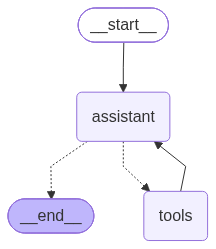

In [6]:
from langgraph.graph import START, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

# 1) construtor do grafo
builder = StateGraph(MessagesState)

# 2) nós
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))

# 3) arestas
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)  # decide tools vs END
builder.add_edge("tools", "assistant")                     # loop

# 4) compilar
graph = builder.compile()

graph

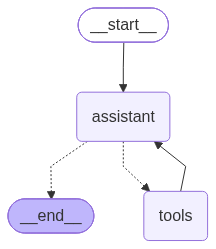

In [7]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph(xray=True).draw_mermaid_png()))
except Exception as e:
    print("Não foi possível renderizar a imagem do grafo aqui.")
    print("Erro:", e)

In [8]:
from langchain_core.messages import HumanMessage

pergunta = (
    "Eu sou o Anderson. Vou viajar para a Bahia (UF=BA). " 
    "Qual é a capital? Além disso, meu jantar custou 180 reais; " 
    "calcule o total com 10% de serviço e depois parcele em 3x. "
    "Responda de forma amigável."
)

result = graph.invoke({"messages": [HumanMessage(content=pergunta)]})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Eu sou o Anderson. Vou viajar para a Bahia (UF=BA). Qual é a capital? Além disso, meu jantar custou 180 reais; calcule o total com 10% de serviço e depois parcele em 3x. Responda de forma amigável.
================================== Ai Message ==================================

Olá, Anderson! A capital da Bahia (BA) é Salvador. Seu jantar de R$ 180,00 com 10 % de serviço ficou R$ 198,00 no total. Parcelando em 3 vezes, cada parcela será de R$ 66,00. Boa viagem e aproveite a Bahia!


In [9]:
from langchain_core.messages import BaseMessage

def last_message_str(messages: list[BaseMessage]) -> str:
    if not messages:
        return "(sem mensagens)"
    m = messages[-1]
    # Alguns tipos (ToolMessage) têm melhor representação via pretty_print()
    return f"{type(m).__name__}: {getattr(m, 'content', '')}"[:2000]

pergunta2 = (
    "Anderson aqui. Meu almoço em Recife deu 95 reais. " 
    "Calcule o total com 10% e depois divida em 2 parcelas."
)

for event in graph.stream({"messages": [HumanMessage(content=pergunta2)]}, stream_mode="values"):
    print("\n--- evento ---")
    print(last_message_str(event["messages"]))


--- evento ---
HumanMessage: Anderson aqui. Meu almoço em Recife deu 95 reais. Calcule o total com 10% e depois divida em 2 parcelas.

--- evento ---
AIMessage: 

--- evento ---
ToolMessage: 104.50000000000001

--- evento ---
AIMessage: (⚠️ Saída fora do protocolo)

O valor total com 10 % de acréscimo ficou em R$ 104,50. Dividindo em 2 parcelas, cada uma será de R$ 52,25.


In [10]:
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()
graph_with_memory = builder.compile(checkpointer=memory)

# A identidade da conversa:
config = {"configurable": {"thread_id": "anderson-thread-1"}}

# 1) Primeiro turno
r1 = graph_with_memory.invoke(
    {"messages": [HumanMessage(content="Anderson: meu jantar foi 120 reais. Calcule o total com 10% de serviço.") ]},
    config=config,
)
print("\n# Turno 1")
for m in r1["messages"]:
    m.pretty_print()

# 2) Segundo turno (follow-up)
r2 = graph_with_memory.invoke(
    {"messages": [HumanMessage(content="Agora pegue esse total e parcele em 4x.") ]},
    config=config,
)
print("\n# Turno 2")
for m in r2["messages"]:
    m.pretty_print()


# Turno 1
================================ Human Message =================================

Anderson: meu jantar foi 120 reais. Calcule o total com 10% de serviço.
================================== Ai Message ==================================

O total do jantar, incluindo 10% de serviço, é R$ 132,00.

# Turno 2
================================ Human Message =================================

Anderson: meu jantar foi 120 reais. Calcule o total com 10% de serviço.
================================== Ai Message ==================================

O total do jantar, incluindo 10% de serviço, é R$ 132,00.
================================ Human Message =================================

Agora pegue esse total e parcele em 4x.
================================== Ai Message ==================================

(⚠️ Saída fora do protocolo)

Cada parcela será de R$ 33,00, totalizando 4 parcelas de R$ 33,00 cada.


In [11]:
config_outro = {"configurable": {"thread_id": "anderson-thread-2"}}

r3 = graph_with_memory.invoke(
    {"messages": [HumanMessage(content="Agora pegue esse total e parcele em 4x.") ]},
    config=config_outro,
)

print("\n# Turno em outra thread (sem contexto anterior)")
for m in r3["messages"]:
    m.pretty_print()


# Turno em outra thread (sem contexto anterior)
================================ Human Message =================================

Agora pegue esse total e parcele em 4x.
================================== Ai Message ==================================

Por favor, informe o valor total que deseja parcelar em 4 vezes.


In [12]:
# Rode esta célula somente se você estiver com o servidor local ativo em http://localhost:2024
# (veja seção 9.2)

import asyncio
from langgraph_sdk import get_client

async def demo_sdk_stream():
    client = get_client(url="http://localhost:2024")
    async for chunk in client.runs.stream(
        None,          # threadless
        "agent",     # assistant_id (chave em langgraph.json)
        input={
            "messages": [
                {"role": "human", "content": "Sou o Anderson. Qual é a capital de SP e quanto fica 50 reais com 10% de serviço?"}
            ]
        },
        stream_mode="values",
    ):
        if chunk.event != "metadata" and chunk.data:
            # para simplificar, mostramos só o último conteúdo
            msgs = chunk.data.get("messages") or []
            if msgs:
                print(msgs[-1])

# asyncio.run(demo_sdk_stream())

In [ ]:
pip install -U "langgraph-cli[inmem]"
